In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(42)
%matplotlib inline

In [2]:
try:
    df = pd.read_csv("iris_Dataset.csv")
    print("Loaded dataset from iris_Dataset.csv")
except FileNotFoundError:

    from sklearn.datasets import load_iris
    iris = load_iris(as_frame=True)
    df = iris.frame.copy()
    df.columns = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'target']
    species_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
    df['Species'] = df['target'].map(species_map)
    df = df.drop(columns=['target'])
    df.insert(0, 'Id', range(1, len(df) + 1))
    print("iris_Dataset.csv not found — loaded built-in sklearn Iris dataset instead (same data).")

df.head()

iris_Dataset.csv not found — loaded built-in sklearn Iris dataset instead (same data).


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,setosa
1,2,4.9,3.0,1.4,0.2,setosa
2,3,4.7,3.2,1.3,0.2,setosa
3,4,4.6,3.1,1.5,0.2,setosa
4,5,5.0,3.6,1.4,0.2,setosa


## 6. Dataset Information

In [3]:
df.shape

(150, 6)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [5]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.057333,3.758000,1.199333
std,43.445368,0.828066,0.435866,1.765298,0.762238
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [6]:
df['Species'].value_counts()

Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### Visualizations

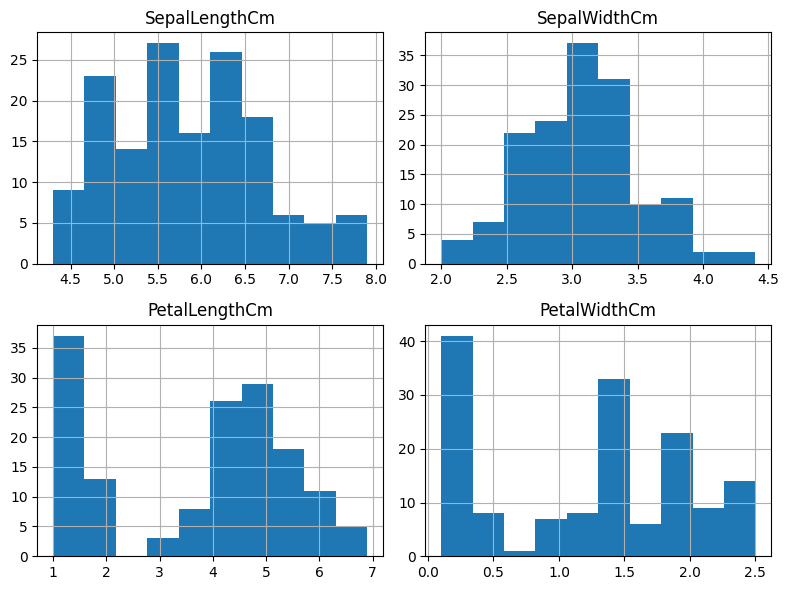

In [7]:
df.drop(columns=['Id']).hist(figsize=(8,6))
plt.tight_layout()
plt.show()

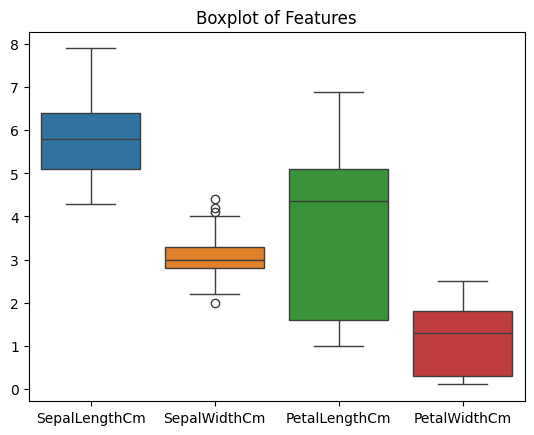

In [8]:
sns.boxplot(data=df.drop(columns=['Id', 'Species']))
plt.title("Boxplot of Features")
plt.show()

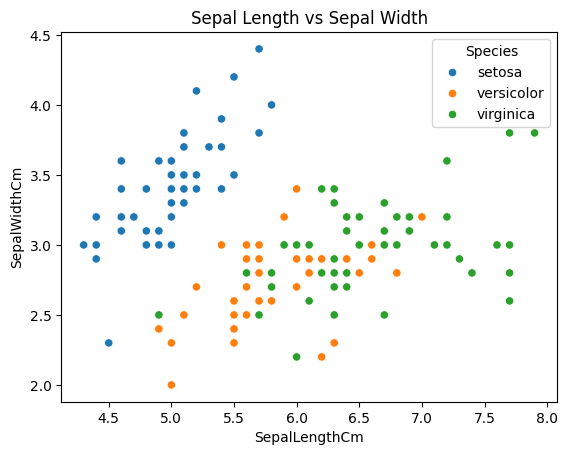

In [9]:
sns.scatterplot(data=df, x='SepalLengthCm', y='SepalWidthCm', hue='Species')
plt.title("Sepal Length vs Sepal Width")
plt.show()

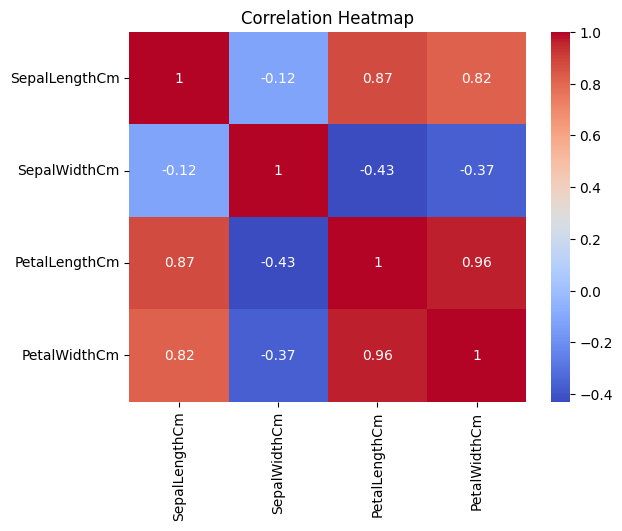

In [10]:
sns.heatmap(df.drop(columns=['Id','Species']).corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [11]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [12]:
df_processed = df.drop(columns=['Id'])

le = LabelEncoder()
df_processed['Species'] = le.fit_transform(df_processed['Species'])
df_processed.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [13]:
X = df_processed.drop(columns=['Species'])
y = df_processed['Species']

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Original number of features:", X.shape[1])

Feature matrix shape: (150, 4)
Target shape: (150,)
Original number of features: 4


In [14]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=2)
selector.fit(X, y)
selected_features = X.columns[selector.get_support()]
print("Top 2 features by ANOVA F-value (reference only, not used downstream):", list(selected_features))

Top 2 features by ANOVA F-value (reference only, not used downstream): ['PetalLengthCm', 'PetalWidthCm']


## 8. Train-Test Split


In [15]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Train size: 120
Test size: 30
Number of features: 4


## 9. WITHOUT PCA

Train the KNN classifier (same algorithm and hyperparameters as the original assignment:
`KNeighborsClassifier(n_neighbors=5)`) directly on the standardized original feature space
(4 features).

### 9.1 Model Training

In [16]:
knn_no_pca = KNeighborsClassifier(n_neighbors=5)
knn_no_pca.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


### 9.2 Prediction

In [17]:
y_pred_no_pca = knn_no_pca.predict(X_test)

### 9.3 Evaluation

In [18]:
accuracy_no_pca = accuracy_score(y_test, y_pred_no_pca)
print("Accuracy (Without PCA):", accuracy_no_pca)

Accuracy (Without PCA): 0.9333333333333333


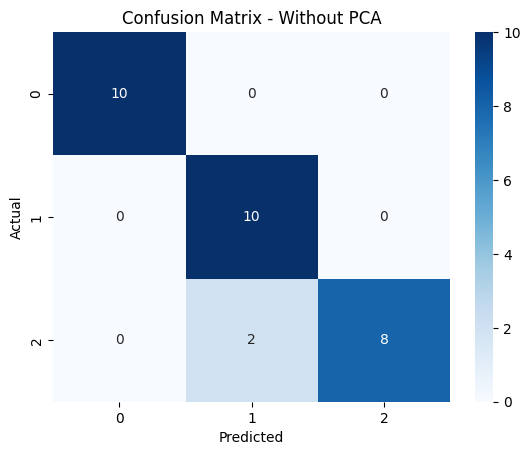

In [19]:
cm_no_pca = confusion_matrix(y_test, y_pred_no_pca)
sns.heatmap(cm_no_pca, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Without PCA")
plt.show()

In [20]:
report_no_pca = classification_report(y_test, y_pred_no_pca, target_names=le.classes_)
print(report_no_pca)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



## 10. PCA

Now we reduce the dimensionality of the (already standardized) feature space using PCA.

**Rules followed:**
- PCA is applied only to the feature matrix `X`, never to the target `y`.
- PCA is **fit only on the training data** (`X_train`, already scaled) and then used to transform
  both the training and test sets — this prevents any leakage from the test set.
- We choose the number of components that retain **95% of the explained variance**, which is a
  sensible default for a small, well-behaved dataset like Iris.

### 10.1 Standardization

Already done in Section 8 (`X_train` / `X_test` are the scaled arrays) — reused directly here.

### 10.2 PCA Fitting

In [21]:
pca_full = PCA()
pca_full.fit(X_train)

explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

print("Explained variance ratio per component:", np.round(explained_var, 4))
print("Cumulative explained variance:", np.round(cumulative_var, 4))

Explained variance ratio per component: [0.7268 0.2307 0.0378 0.0047]
Cumulative explained variance: [0.7268 0.9574 0.9953 1.    ]


In [22]:
n_components_95 = np.argmax(cumulative_var >= 0.95) + 1
print(f"Original number of features: {X_train.shape[1]}")
print(f"Number of PCA components needed for >=95% variance: {n_components_95}")

Original number of features: 4
Number of PCA components needed for >=95% variance: 2


In [23]:
pca = PCA(n_components=n_components_95, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Shape before PCA:", X_train.shape)
print("Shape after PCA:", X_train_pca.shape)
print("Explained variance ratio (selected components):", np.round(pca.explained_variance_ratio_, 4))
print("Total variance retained: {:.2f}%".format(pca.explained_variance_ratio_.sum() * 100))

Shape before PCA: (120, 4)
Shape after PCA: (120, 2)
Explained variance ratio (selected components): [0.7268 0.2307]
Total variance retained: 95.74%


### 10.3 Scree / Cumulative Explained Variance Plot

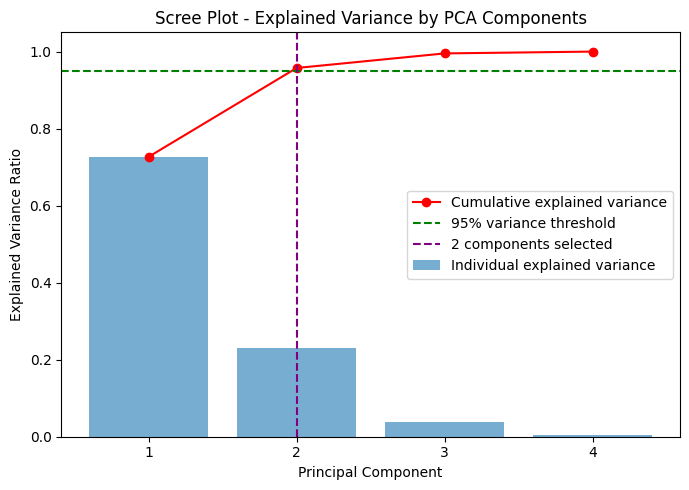

In [24]:
plt.figure(figsize=(7,5))
components = np.arange(1, len(explained_var) + 1)
plt.bar(components, explained_var, alpha=0.6, label='Individual explained variance')
plt.plot(components, cumulative_var, marker='o', color='red', label='Cumulative explained variance')
plt.axhline(y=0.95, color='green', linestyle='--', label='95% variance threshold')
plt.axvline(x=n_components_95, color='purple', linestyle='--', label=f'{n_components_95} components selected')
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot - Explained Variance by PCA Components")
plt.xticks(components)
plt.legend()
plt.tight_layout()
plt.show()

## 11. WITH PCA

Train the **same** KNN classifier (`n_neighbors=5`) on the PCA-transformed training data, and
evaluate it on the PCA-transformed test data.

### 11.1 Model Training

In [25]:
knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train_pca, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


### 11.2 Prediction

In [26]:
y_pred_pca = knn_pca.predict(X_test_pca)

### 11.3 Evaluation

In [27]:
accuracy_pca = accuracy_score(y_test, y_pred_pca)
print("Accuracy (With PCA):", accuracy_pca)

Accuracy (With PCA): 0.9


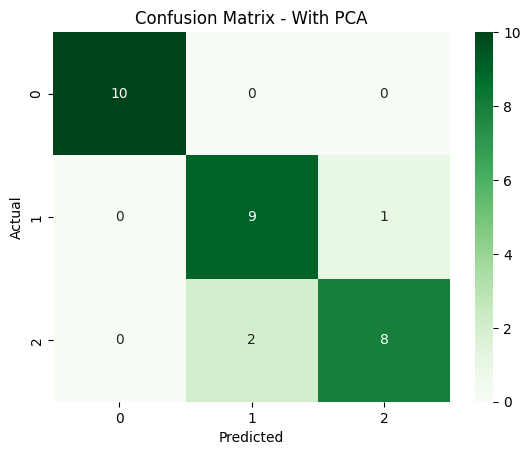

In [28]:
cm_pca = confusion_matrix(y_test, y_pred_pca)
sns.heatmap(cm_pca, annot=True, fmt='d', cmap='Greens')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - With PCA")
plt.show()

In [29]:
report_pca = classification_report(y_test, y_pred_pca, target_names=le.classes_)
print(report_pca)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



## 12. Comparison: Without PCA vs With PCA

In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score

comparison_df = pd.DataFrame({
    "Metric": ["Number of Features", "Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"],
    "Without PCA": [
        X_train.shape[1],
        accuracy_score(y_test, y_pred_no_pca),
        precision_score(y_test, y_pred_no_pca, average='macro'),
        recall_score(y_test, y_pred_no_pca, average='macro'),
        f1_score(y_test, y_pred_no_pca, average='macro'),
    ],
    "With PCA": [
        X_train_pca.shape[1],
        accuracy_score(y_test, y_pred_pca),
        precision_score(y_test, y_pred_pca, average='macro'),
        recall_score(y_test, y_pred_pca, average='macro'),
        f1_score(y_test, y_pred_pca, average='macro'),
    ],
})
comparison_df

,Metric,Without PCA,With PCA
0,Number of Features,4.000000,2.000000
1,Accuracy,0.933333,0.900000
2,Precision (macro),0.944444,0.902357
3,Recall (macro),0.933333,0.900000
4,F1-score (macro),0.932660,0.899749


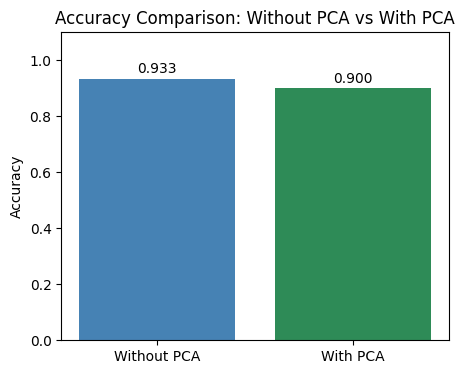

In [31]:
labels = ['Without PCA', 'With PCA']
values = [accuracy_no_pca, accuracy_pca]

plt.figure(figsize=(5,4))
bars = plt.bar(labels, values, color=['steelblue', 'seagreen'])
plt.ylim(0, 1.1)
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison: Without PCA vs With PCA")
for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha='center')
plt.show()

## 13. Observation

- The dataset originally has **4 features** (`SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`).
- PCA reduced this to the smallest number of components that still retain **at least 95%** of the
  total variance (see Section 10.2 for the exact number and variance retained on this run).
- Compare the printed accuracy/precision/recall/F1 values above (Section 12 table) to see whether
  PCA improved, matched, or slightly reduced performance relative to the original feature space.
- The Iris dataset is small, low-dimensional, and its classes are already well-separated by the
  petal measurements, so KNN performance with and without PCA is typically very close — any small
  differences are usually due to reduced noise (potential slight improvement) or minor loss of
  discriminative information (potential slight drop) when compressing 4 features into fewer
  components.

## 14. Conclusion

This notebook trained the same K-Nearest Neighbors classifier on the Iris dataset in two settings:
directly on the standardized 4-dimensional feature space (**Without PCA**), and on a
lower-dimensional space obtained via PCA retaining ~95% of the variance (**With PCA**). Both
pipelines used an identical, leakage-free train/test split and scaler, so the comparison in
Section 12 reflects the effect of dimensionality reduction alone. Based on the results above,
PCA is able to substantially compress the feature space for this dataset while keeping predictive
performance very close to the full-feature model, since most of the class-discriminative
information in Iris is concentrated in a small number of principal directions (dominated by the
strongly correlated petal length/width measurements).